# Model training

Trains ResNet18 on the regular and augmented datasets (5 seeds each). Results are saved to `results/`.

In [1]:
#Imports
import copy
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

In [2]:
#Settings
SEEDS = [0, 1, 2, 3, 4] #5 runs per condition
CONDITIONS = ["regular", "augmented"]

BATCH_SIZE = 32
LEARNING_RATE = 1e-4 #small, so pretrained weights change gently
WEIGHT_DECAY = 1e-4

MAX_STEPS = 600 #same number of updates for both conditions
EVAL_EVERY = 50 #check validation every 50 steps
PATIENCE = 4 #stop after 4 checks without improvement

NUM_WORKERS = 4
torch.set_num_threads(os.cpu_count())

In [3]:
# Paths
PROJECT_DIR = Path.cwd()

data_path = PROJECT_DIR / "processed_data"
results_path = PROJECT_DIR / "results"
models_path = PROJECT_DIR / "models"

assert data_path.exists(), (
    f"Processed data not found at: {data_path}. Run preprocessing.ipynb first."
)

results_path.mkdir(exist_ok=True)
models_path.mkdir(exist_ok=True)

print("Data:", data_path.relative_to(PROJECT_DIR))
print("Results:", results_path.relative_to(PROJECT_DIR))
print("Models:", models_path.relative_to(PROJECT_DIR))

Data: processed_data
Results: results
Models: models


In [4]:
#Load data
#Convert to tensors and normalise with ImageNet stats
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


def load_split(condition, split):
    return datasets.ImageFolder(
        root=data_path / condition / split,
        transform=transform
    )


#Val and test are the same in both conditions
val_dataset = load_split("regular", "val")
test_dataset = load_split("regular", "test")

classes = test_dataset.classes

print("Classes:", classes)
for condition in CONDITIONS:
    print(f"{condition} train:", len(load_split(condition, "train")))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Classes: ['jerry', 'tom', 'tom_jerry_0', 'tom_jerry_1']
regular train: 1369
augmented train: 2738
Validation: 1370
Test: 2739


In [5]:
#Model
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def build_model():
    #Pretrained ResNet18 with a new 4-class output layer
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, len(classes))
    return model


def build_optimizer(model):
    #No weight decay on biases and BatchNorm
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]

    return torch.optim.AdamW([
        {"params": decay, "weight_decay": WEIGHT_DECAY},
        {"params": no_decay, "weight_decay": 0.0}
    ], lr=LEARNING_RATE)


criterion = nn.CrossEntropyLoss()

In [6]:
#Evaluation
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probs = []

    for images, labels in loader:
        logits = model(images)
        total_loss += criterion(logits, labels).item() * len(labels)
        all_labels.append(labels)
        all_probs.append(torch.softmax(logits, dim=1))

    labels = torch.cat(all_labels)
    probs = torch.cat(all_probs)
    accuracy = (probs.argmax(dim=1) == labels).float().mean().item()

    return total_loss / len(labels), accuracy, labels, probs

In [7]:
#Training
def train_one_run(condition, seed):

    set_seed(seed)

    train_loader = DataLoader(
        load_split(condition, "train"),
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=NUM_WORKERS
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=64,
        num_workers=NUM_WORKERS
    )

    model = build_model()
    optimizer = build_optimizer(model)

    history = []
    best_val_loss = float("inf")
    best_state = None
    best_step = 0
    checks_without_improvement = 0

    step = 0
    running_loss = 0.0
    batches = iter(train_loader)

    while step < MAX_STEPS:

        #Restart the training set when it runs out
        try:
            images, labels = next(batches)
        except StopIteration:
            batches = iter(train_loader)
            images, labels = next(batches)

        model.train()
        loss = criterion(model(images), labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        step += 1
        running_loss += loss.item()

        if step % EVAL_EVERY == 0:

            val_loss, val_accuracy, _, _ = evaluate(model, val_loader)

            history.append({
                "step": step,
                "train_loss": running_loss / EVAL_EVERY,
                "val_loss": val_loss,
                "val_accuracy": val_accuracy
            })
            running_loss = 0.0

            print(
                f"  step {step:4d} | "
                f"train loss {history[-1]['train_loss']:.3f} | "
                f"val loss {val_loss:.3f} | "
                f"val acc {val_accuracy:.3f}"
            )

            #Keep the checkpoint with the lowest validation loss
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                best_step = step
                checks_without_improvement = 0
            else:
                checks_without_improvement += 1

                if checks_without_improvement >= PATIENCE:
                    print(f"  Early stopping at step {step}")
                    break

    model.load_state_dict(best_state)

    return model, history, best_step, best_val_loss

In [8]:
#Save configuration
config = {
    "model": "resnet18, ImageNet pretrained (IMAGENET1K_V1), new 4-class output layer",
    "fine_tuning": "all layers",
    "loss": "cross-entropy",
    "optimiser": "AdamW, no weight decay on biases and BatchNorm",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "max_steps": MAX_STEPS,
    "eval_every": EVAL_EVERY,
    "patience": PATIENCE,
    "checkpoint": "lowest validation loss",
    "seeds": SEEDS,
    "conditions": CONDITIONS,
    "classes": classes,
    "normalisation": "ImageNet mean and std",
    "data": {
        "source": "processed_data/ from preprocessing.ipynb (seed 42, temporal 25/25/50 split)",
        "train_images": {c: len(load_split(c, "train")) for c in CONDITIONS},
        "val_images": len(val_dataset),
        "test_images": len(test_dataset)
    },
    "parameters": sum(p.numel() for p in build_model().parameters()),
    "hardware": "CPU only (12 cores, 14GB RAM)",
    "torch_version": torch.__version__
}

(results_path / "config.json").write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))


{
  "model": "resnet18, ImageNet pretrained (IMAGENET1K_V1), new 4-class output layer",
  "fine_tuning": "all layers",
  "loss": "cross-entropy",
  "optimiser": "AdamW, no weight decay on biases and BatchNorm",
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "batch_size": 32,
  "max_steps": 600,
  "eval_every": 50,
  "patience": 4,
  "checkpoint": "lowest validation loss",
  "seeds": [
    0,
    1,
    2,
    3,
    4
  ],
  "conditions": [
    "regular",
    "augmented"
  ],
  "classes": [
    "jerry",
    "tom",
    "tom_jerry_0",
    "tom_jerry_1"
  ],
  "normalisation": "ImageNet mean and std",
  "data": {
    "source": "processed_data/ from preprocessing.ipynb (seed 42, temporal 25/25/50 split)",
    "train_images": {
      "regular": 1369,
      "augmented": 2738
    },
    "val_images": 1370,
    "test_images": 2739
  },
  "parameters": 11178564,
  "hardware": "CPU only (12 cores, 14GB RAM)",
  "torch_version": "2.14.1+cpu"
}


In [9]:
#Run all experiments
#Test set is used once per run, after training
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    num_workers=NUM_WORKERS
)

for condition in CONDITIONS:

    for seed in SEEDS:

        run_name = f"{condition}_seed{seed}"
        result_file = results_path / f"{run_name}.json"

        if result_file.exists():
            print(f"Skipping {run_name}: already done")
            continue

        print(f"\nTraining {run_name}")
        start = time.time()

        model, history, best_step, best_val_loss = train_one_run(condition, seed)

        test_loss, test_accuracy, labels, probs = evaluate(model, test_loader)
        predicted = probs.argmax(dim=1)

        torch.save(model.state_dict(), models_path / f"{run_name}.pt")

        #Save test predictions for evaluation
        predictions = pd.DataFrame(
            probs.numpy(),
            columns=[f"prob_{c}" for c in classes]
        )
        predictions.insert(0, "image", [
            str(Path(path).relative_to(PROJECT_DIR)) for path, _ in test_dataset.samples
        ])
        predictions.insert(1, "label", [classes[i] for i in labels])
        predictions.insert(2, "predicted", [classes[i] for i in predicted])
        predictions.to_csv(
            results_path / f"{run_name}_test_predictions.csv",
            index=False
        )

        result = {
            "condition": condition,
            "seed": seed,
            "best_step": best_step,
            "best_val_loss": best_val_loss,
            "test_loss": test_loss,
            "test_accuracy": test_accuracy,
            "minutes": (time.time() - start) / 60,
            "history": history
        }
        result_file.write_text(json.dumps(result, indent=2))

        print(
            f"Done {run_name}: test acc {test_accuracy:.3f}, "
            f"test loss {test_loss:.3f}, {result['minutes']:.1f} min"
        )

Skipping regular_seed0: already done
Skipping regular_seed1: already done
Skipping regular_seed2: already done
Skipping regular_seed3: already done
Skipping regular_seed4: already done

Training augmented_seed0
  step   50 | train loss 0.640 | val loss 1.464 | val acc 0.577
  step  100 | train loss 0.224 | val loss 1.314 | val acc 0.601
  step  150 | train loss 0.080 | val loss 1.571 | val acc 0.603
  step  200 | train loss 0.052 | val loss 1.376 | val acc 0.615
  step  250 | train loss 0.034 | val loss 1.521 | val acc 0.586
  step  300 | train loss 0.015 | val loss 1.280 | val acc 0.639
  step  350 | train loss 0.017 | val loss 1.421 | val acc 0.618
  step  400 | train loss 0.013 | val loss 1.265 | val acc 0.582
  step  450 | train loss 0.015 | val loss 1.382 | val acc 0.615
  step  500 | train loss 0.011 | val loss 1.673 | val acc 0.574
  step  550 | train loss 0.006 | val loss 1.527 | val acc 0.593
  step  600 | train loss 0.004 | val loss 1.657 | val acc 0.599
  Early stopping at s

In [10]:
#Summary
runs = pd.DataFrame([
    json.loads((results_path / f"{c}_seed{s}.json").read_text())
    for c in CONDITIONS
    for s in SEEDS
]).drop(columns="history")

print(runs[["condition", "seed", "best_step", "test_accuracy", "test_loss"]])

summary = runs.groupby("condition", sort=False)[["test_accuracy", "test_loss"]].agg(["mean", "std"])
summary.to_csv(results_path / "summary.csv")

print("\nMean and standard deviation over seeds")
print(summary)

   condition  seed  best_step  test_accuracy  test_loss
0    regular     0        100       0.580869   1.273263
1    regular     1        100       0.627236   1.081218
2    regular     2        100       0.564074   1.334132
3    regular     3        150       0.610442   1.286977
4    regular     4         50       0.592917   1.214620
5  augmented     0        400       0.593282   1.349778
6  augmented     1        100       0.634538   1.059561
7  augmented     2         50       0.527565   1.463133
8  augmented     3        100       0.608251   1.329839
9  augmented     4        200       0.624681   1.263402

Mean and standard deviation over seeds
          test_accuracy           test_loss          
                   mean       std      mean       std
condition                                            
regular        0.595108  0.024688  1.238042  0.097482
augmented      0.597663  0.042234  1.293143  0.149077


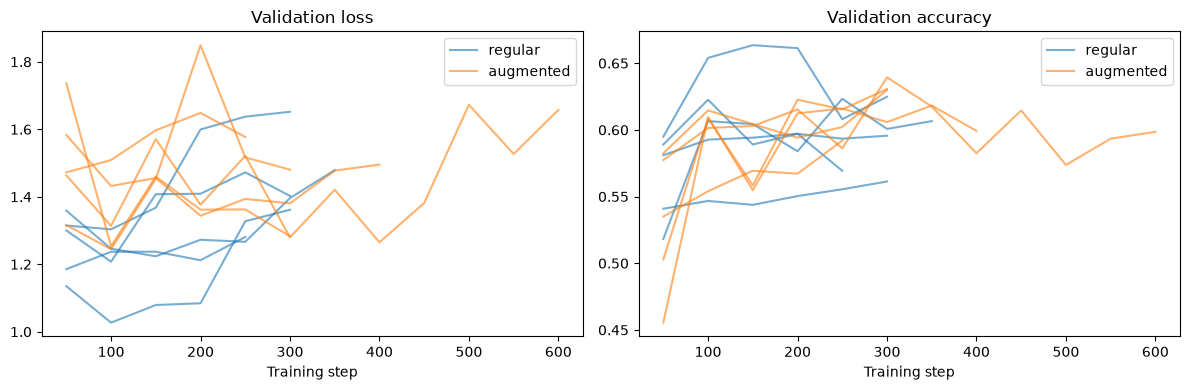

In [11]:
#Validation curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for condition, colour in zip(CONDITIONS, ["tab:blue", "tab:orange"]):
    for seed in SEEDS:
        history = pd.DataFrame(
            json.loads((results_path / f"{condition}_seed{seed}.json").read_text())["history"]
        )
        label = condition if seed == SEEDS[0] else None
        axes[0].plot(history["step"], history["val_loss"], color=colour, alpha=0.6, label=label)
        axes[1].plot(history["step"], history["val_accuracy"], color=colour, alpha=0.6, label=label)

axes[0].set_title("Validation loss")
axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Training step")
    ax.legend()

plt.tight_layout()
plt.show()

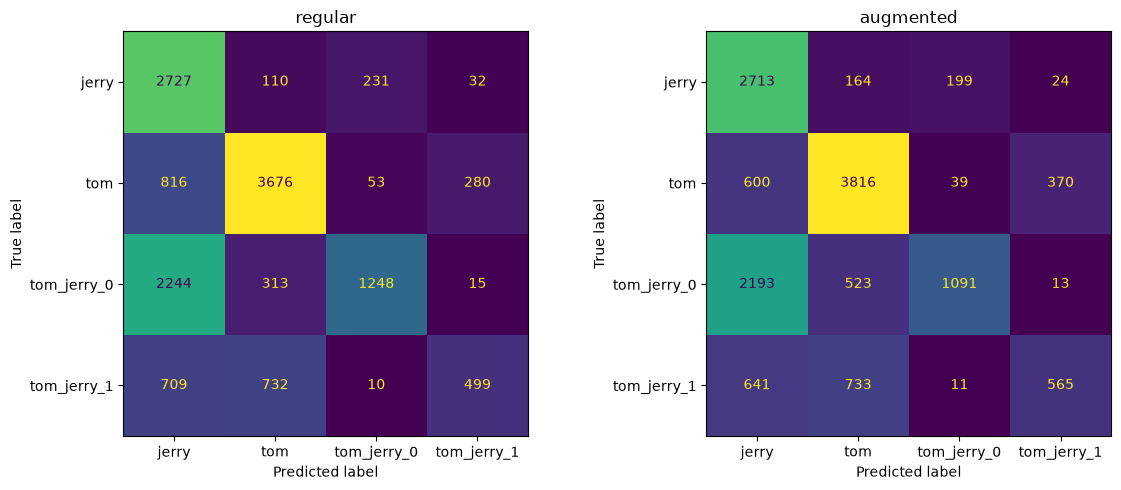

In [12]:
#Confusion matrices (test set, all seeds combined)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, condition in zip(axes, CONDITIONS):

    predictions = pd.concat([
        pd.read_csv(results_path / f"{condition}_seed{seed}_test_predictions.csv")
        for seed in SEEDS
    ])

    matrix = confusion_matrix(
        predictions["label"],
        predictions["predicted"],
        labels=classes
    )

    ConfusionMatrixDisplay(matrix, display_labels=classes).plot(ax=ax, colorbar=False)
    ax.set_title(condition)

plt.tight_layout()
plt.show()